# Lecture 2 — Model Answer
## Bar Charts: World Happiness Report 2023



---


In [1]:
import pandas as pd
import numpy as np
import plotly.express as px

# Dataset: World Happiness Report 2023
# Real dataset: https://www.kaggle.com/datasets/ajaypalsinghlo/world-happiness-report-2023
# Place the downloaded CSV at: data/world_happiness_2023.csv
df = pd.read_csv('../data/world_happiness_2023.csv')

# Rename columns for convenience
df.columns = ['Country','Region','Happiness_Score','GDP','Social_Support',
              'Life_Expectancy','Freedom','Generosity','Corruption']
print(f"{len(df)} countries loaded")
print(df.head())


63 countries loaded
       Country                        Region  Happiness_Score     GDP  \
0      Finland                Western Europe            7.804  10.775   
1      Denmark                Western Europe            7.586  10.933   
2      Iceland                Western Europe            7.525  10.878   
3       Israel  Middle East and North Africa            7.473  10.527   
4  Netherlands                Western Europe            7.464  11.015   

   Social_Support  Life_Expectancy  Freedom  Generosity  Corruption  
0           0.954             71.9    0.949       0.142       0.179  
1           0.954             72.7    0.931       0.168       0.234  
2           0.983             72.5    0.961       0.260       0.150  
3           0.916             72.4    0.903       0.149       0.826  
4           0.939             72.4    0.879       0.240       0.296  


---
## Task 1 — Regional Comparison Bar Chart

**Story:** Western Europe sits in a league of its own — more than 1.5 points above the nearest region. Sub-Saharan Africa and South Asia trail by over 2.5 points.


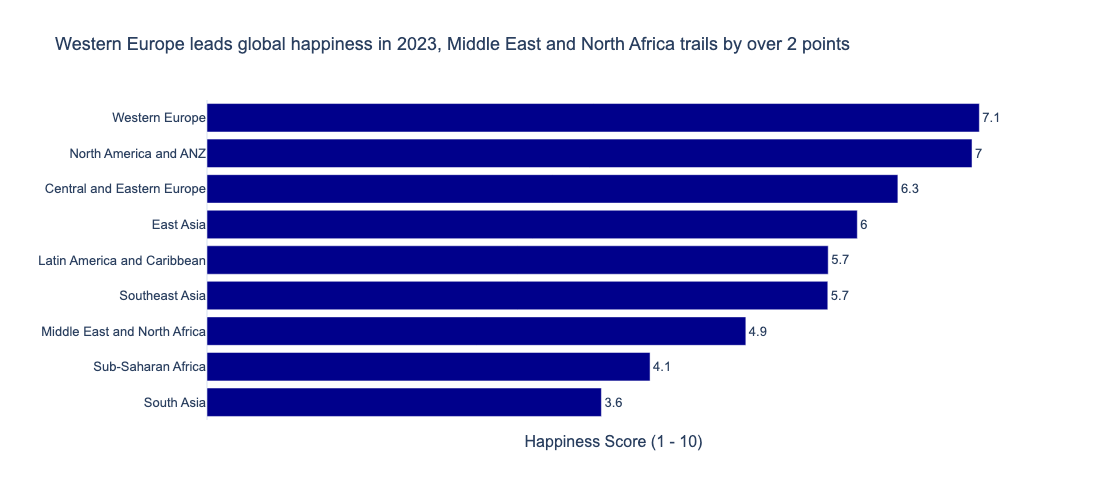

In [10]:

# prep data
region_avg = df.groupby('Region')['Happiness_Score'].mean().reset_index().sort_values('Happiness_Score')

# create a plotly express
fig = px.bar(
    data_frame=region_avg,
    x='Happiness_Score', 
    y='Region', 
    text=region_avg['Happiness_Score'].round(1), # text over or inside the bars
    title='Western Europe leads global happiness in 2023, Middle East and North Africa trails by over 2 points',
    labels={'Happiness_Score': 'Happiness Score (1 - 10)'},
    template='plotly_white',
    color_discrete_sequence=['darkblue'],
    height=500
)



# add needed customizations

fig.update_traces(
    textposition='outside' # controls where the text on the bars is positioned
)

fig.update_layout(
    xaxis=dict(showgrid=False, showticklabels=False),
    yaxis=dict(title=''),
    font=dict(family='Arial', size=13),
)




fig.show()

---
## Task 2 — Bottom vs. Top: A Contrast Story


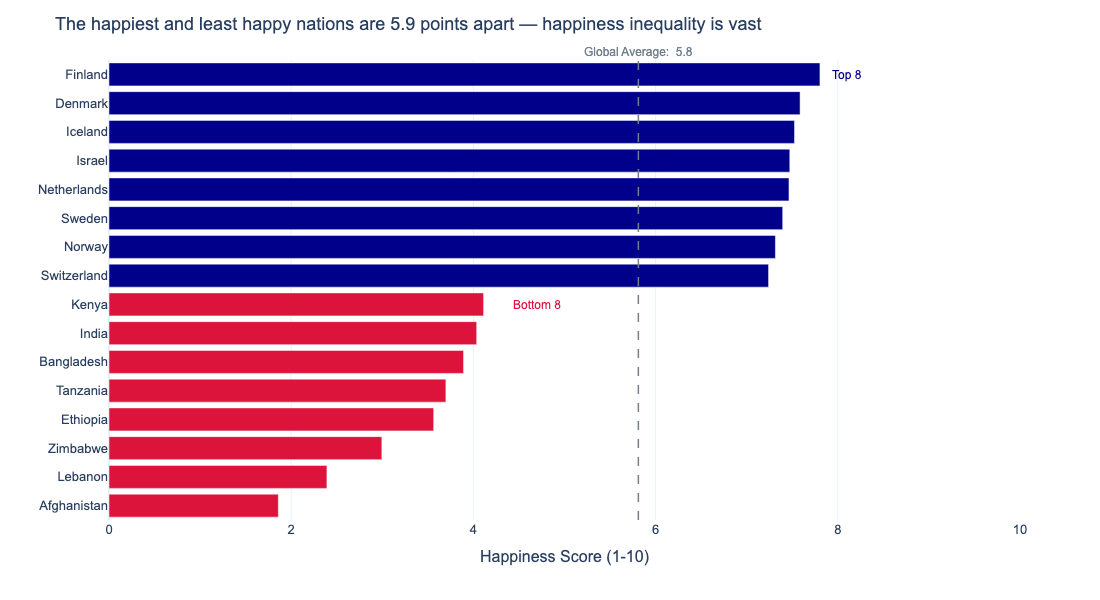

In [14]:
# prep data
top8 = df.nlargest(8,'Happiness_Score').assign(Group='Top 8')
bottom8 = df.nsmallest(8,'Happiness_Score').assign(Group='Bottom 8')

combined = pd.concat([bottom8, top8]).sort_values('Happiness_Score').reset_index(drop=True)

global_avg = df['Happiness_Score'].mean()


fig = px.bar(
    data_frame=combined,
    x='Happiness_Score', y='Country',
    orientation='h',
    color='Group',
    color_discrete_map={'Top 8': 'darkblue', 'Bottom 8': 'crimson'},
    hover_data={'Region': True, 'Happiness_Score': ':.1f', 'Group': False},
    template='plotly_white',
    labels={'Happiness_Score': 'Happiness Score (1-10)'},
    height=500
)


text_vline = f'Global Average: {global_avg: .1f}'

# adding the average vertical line
fig.add_vline(x=global_avg, 
              line_dash='dash', line_color='slategrey', line_width=1.5,
              annotation_text=text_vline,
              annotation_position='top', 
              annotation_font=dict(size=12, color='slategrey'))


# adding the text highlighting the gap, top and bottom numbers- global average reference line gives a meaningful anchor 


gap = top8['Happiness_Score'].max() - bottom8['Happiness_Score'].min()

fig.add_annotation(x=8.1, y='Finland', 
                   text='Top 8',
                   showarrow=False, 
                   font=dict(color='darkblue', size=12))

fig.add_annotation(x=4.7, y='Kenya', 
                   text='Bottom 8',
                   showarrow=False, 
                   font=dict(color='crimson', size=12))

fig.update_layout(
    title=f'The happiest and least happy nations are {gap:.1f} points apart — happiness inequality is vast',
    xaxis=dict(range=[0, 10]),
    yaxis=dict(title=''),
    font=dict(family='Arial', size=13),
    showlegend=False,
    height=600
)




fig.show()


In [12]:
combined

,Country,Region,Happiness_Score,GDP,Social_Support,Life_Expectancy,Freedom,Generosity,Corruption,Group
0,Afghanistan,South Asia,1.859,6.180,0.374,47.5,0.382,-0.055,0.934,Bottom 8
1,Lebanon,Middle East and North Africa,2.392,7.650,0.486,60.5,0.444,0.049,0.874,Bottom 8
2,Zimbabwe,Sub-Saharan Africa,2.995,6.412,0.476,43.5,0.430,0.057,0.816,Bottom 8
3,Ethiopia,Sub-Saharan Africa,3.564,6.480,0.458,49.4,0.567,0.270,0.822,Bottom 8
4,Tanzania,Sub-Saharan Africa,3.698,6.936,0.525,52.4,0.600,0.258,0.797,Bottom 8
5,Bangladesh,South Asia,3.892,7.305,0.579,59.9,0.578,0.241,0.779,Bottom 8
6,India,South Asia,4.036,7.469,0.639,57.3,0.615,0.265,0.772,Bottom 8
7,Kenya,Sub-Saharan Africa,4.112,7.184,0.558,55.2,0.680,0.331,0.861,Bottom 8
8,Switzerland,Western Europe,7.240,11.117,0.942,74.1,0.921,0.244,0.283,Top 8
9,Norway,Western Europe,7.315,11.072,0.960,72.0,0.939,0.271,0.216,Top 8
